# Día 2 · UMAP: del grafo local al mapa
**16 de octubre de 2026 · 120 minutos · Comparación responsable**

Al terminar podrá construir un grafo difuso, implementar una optimización densa
pequeña y elegir entre PCA, t-SNE y UMAP con evidencia cuantitativa.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'datasets/semana-09').is_dir())
PROJECT = ROOT / 'notebooks/semana-09/proyecto_reduccion'
sys.path.insert(0, str(PROJECT / 'src'))
DATA = ROOT / 'datasets/semana-09'
RESULTS = ROOT / 'notebooks/semana-09/resultados'

from manifold_lab import (HARDatasetLoader, TSNEConfig, UMAPConfig,
                          TSNEFromScratch, UMAPFromScratch,
                          EmbeddingEvaluator, EmbeddingResult)

dataset = HARDatasetLoader(DATA).load()
cache = np.load(RESULTS / 'embeddings_har.npz')
selected = cache['selected']
metadata = dataset.metadata.iloc[selected].reset_index(drop=True)
X50 = cache['pca50'].astype(float)
print(f'Muestra: {len(dataset.metadata):,} filas x {dataset.features.shape[1]} variables')
print(f'Atlas comparativo: {len(selected):,} filas; etiquetas ocultas durante el ajuste.')

D:\Documentos\Universidad Externado\Pregrado en Ciencia de Datos\Machine Learning 2\.venv-week9\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Muestra: 3,600 filas x 561 variables
Atlas comparativo: 1,800 filas; etiquetas ocultas durante el ajuste.


## 1. Cada punto necesita su propia regla local

UMAP comienza con (k) vecinos. ρ conserva conectividad inmediata y σ adapta
la escala local:

$$w_{i\to j}=\exp\left[-\frac{\max(0,d(x_i,x_j)-\rho_i)}{\sigma_i}\right].$$

Luego une direcciones:

$$w_{ij}=w_{i\to j}+w_{j\to i}-w_{i\to j}w_{j\to i}.$$

In [2]:
from sklearn.datasets import make_s_curve
from manifold_lab.umap_model import fuzzy_neighbor_graph

toy, color = make_s_curve(120, noise=.03, random_state=42)
graph = fuzzy_neighbor_graph(toy, n_neighbors=12)
assert np.allclose(graph, graph.T)
print('Aristas con peso:', (graph > 0).sum() // 2,
      '| rango:', graph.min(), graph.max())

Aristas con peso: 834 | rango: 0.0 1.0


### Para resolver

Dibuje los vecinos de un punto denso y otro aislado. Explique por qué usar un
único radio global sería problemático.

**Mi respuesta:** _incluya el papel de rho y sigma_.

## 2. La optimización compara dos grafos

En el plano, la pertenencia suave es
(v_{ij}=[1+a\lVert y_i-y_j\rVert^{2b}]^{-1}). La entropía cruzada
atrae aristas con peso alto y separa pares sin conexión. La clase didáctica usa
todos los pares; `umap-learn` usa muestreo negativo y búsqueda aproximada.

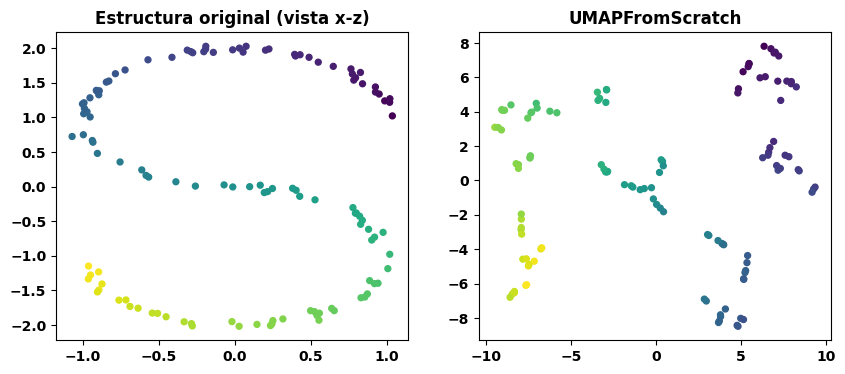

Pérdida final: 0.0784


In [3]:
small = UMAPFromScratch(UMAPConfig(n_neighbors=12, min_dist=.1,
                                   n_epochs=240, learning_rate=.2))
Y = small.fit_transform(toy)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(toy[:, 0], toy[:, 2], c=color, cmap='viridis', s=18)
axes[0].set_title('Estructura original (vista x-z)')
axes[1].scatter(*Y.T, c=color, cmap='viridis', s=18)
axes[1].set_title('UMAPFromScratch')
plt.show()
print('Pérdida final:', round(small.history_[-1], 4))

## 3. Dos hiperparámetros, dos preguntas

- `n_neighbors`: escala local usada para construir el grafo.
- `min_dist`: compactación permitida en la representación final.

No existe una combinación universalmente correcta: debe corresponder a la
pregunta y resistir una auditoría de estabilidad.

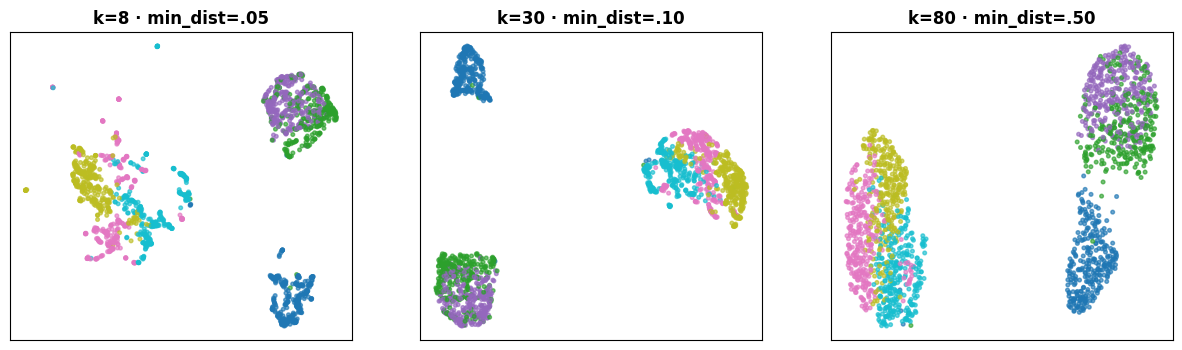

In [4]:
activity = pd.Categorical(metadata.activity).codes
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, title in zip(axes,
    ['umap_8_005', 'umap_30_01', 'umap_80_05'],
    ['k=8 · min_dist=.05', 'k=30 · min_dist=.10', 'k=80 · min_dist=.50']):
    ax.scatter(*cache[key].T, c=activity, cmap='tab10', s=7, alpha=.65)
    ax.set(title=title, xticks=[], yticks=[])
plt.show()

## 4. Comparar mapas exige más que mirarlos

`trustworthiness` penaliza vecinos falsos según su rango original. El
solapamiento cuenta vecinos retenidos. Ninguna de las dos valida el significado
sustantivo de los grupos.

In [5]:
evaluator = EmbeddingEvaluator(n_neighbors=15)
rows = []
for key in ['pca', 'tsne_30', 'umap_30_01']:
    result = EmbeddingResult(key, cache[key].astype(float), {}, 0.0)
    rows.append({'método': key, **evaluator.evaluate(X50, result).as_dict()})
comparison = pd.DataFrame(rows).round(3)
comparison

,método,trustworthiness,neighbor_overlap,distance_correlation,duration_seconds
0,pca,0.898,0.122,0.961,0.0
1,tsne_30,0.978,0.411,0.776,0.0
2,umap_30_01,0.969,0.340,0.874,0.0


## Decisión del equipo

Entregue una recomendación de cinco a ocho líneas:

> Observo → cuantifico → interpreto → comprobaría → no puedo concluir.

Incluya una lectura por actividad, una auditoría por participante y una prueba de
sensibilidad. No elija el mapa únicamente porque separa mejor los colores.

In [6]:
# Puerta de calidad: ejecutar desde proyecto_reduccion.
commands = [
    'python -m flake8 src tests',
    'python -m mypy --strict src',
    'python -m pylint --fail-under=9.5 src tests',
    'python -m pytest --cov=manifold_lab --cov-fail-under=85',
]
print('\n'.join(commands))

python -m flake8 src tests
python -m mypy --strict src
python -m pylint --fail-under=9.5 src tests
python -m pytest --cov=manifold_lab --cov-fail-under=85


## Ticket individual

1. ¿Qué diferencia hay entre `n_neighbors` y `min_dist`?
2. ¿Qué significa preservar topología en este contexto y qué no garantiza UMAP?
3. ¿Qué cambiaría en la arquitectura para agregar Isomap sin tocar el notebook?